<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/MACHINELEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#SAMUEL DAVID CELIS JEREMICHE, CLUSTERING

#Importación de librerías científicas necesarias
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 2. Generación de un Dataset Sintético Multidimensional (6 características)
# Simulamos un escenario complejo sin etiquetas previas con 4 agrupaciones naturales
X, _ = make_blobs(n_samples=500, n_features=6, centers=4, cluster_std=0.8, random_state=42)

print(f"Dimensiones originales del dataset: {X.shape}")


Dimensiones originales del dataset: (500, 6)


In [2]:
#reduccion de dimensionalidad


pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

print(f"Varianza explicada por las 2 componentes principales (PCA): {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X)

Varianza explicada por las 2 componentes principales (PCA): 91.12%


In [4]:

#MODELADO DE CLUSTERING (K-Means y Clustering Jerárquico)


kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
y_kmeans = kmeans.fit_predict(X_pca)
centroides_kmeans = kmeans.cluster_centers_


jerarquico = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
y_jerarquico = jerarquico.fit_predict(X_pca)

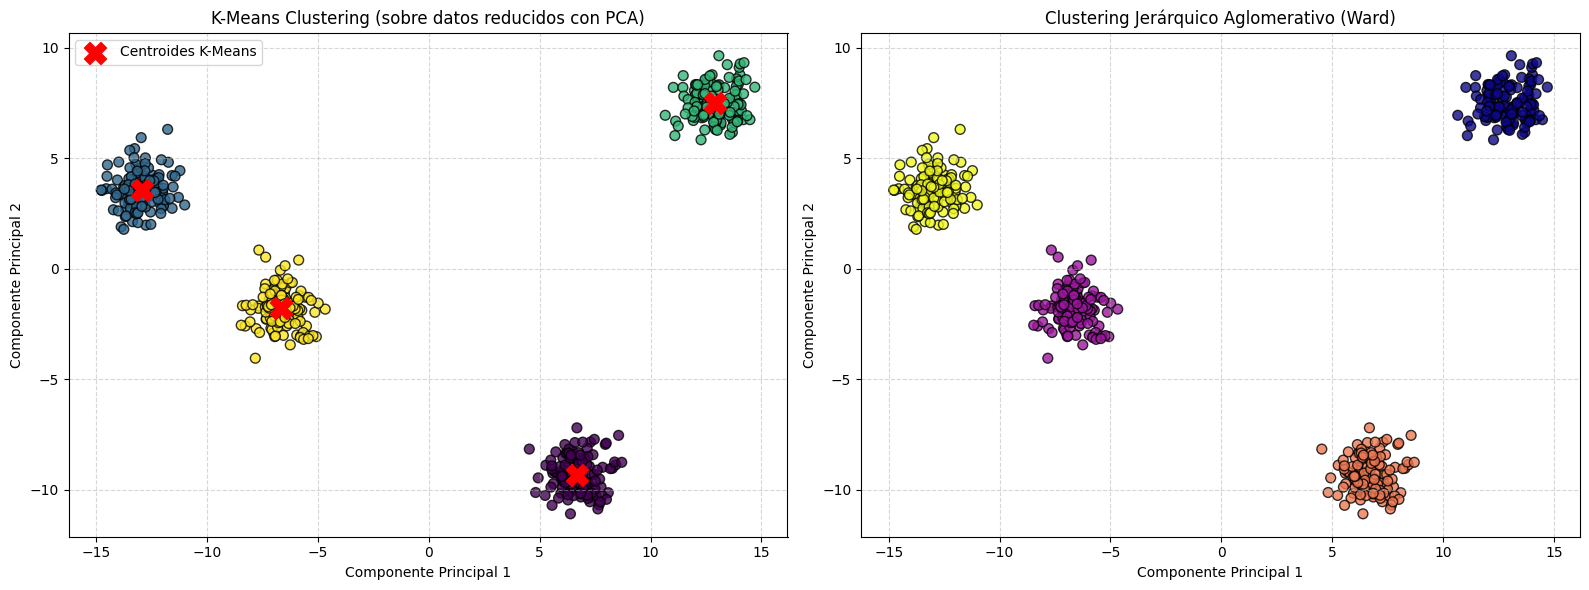

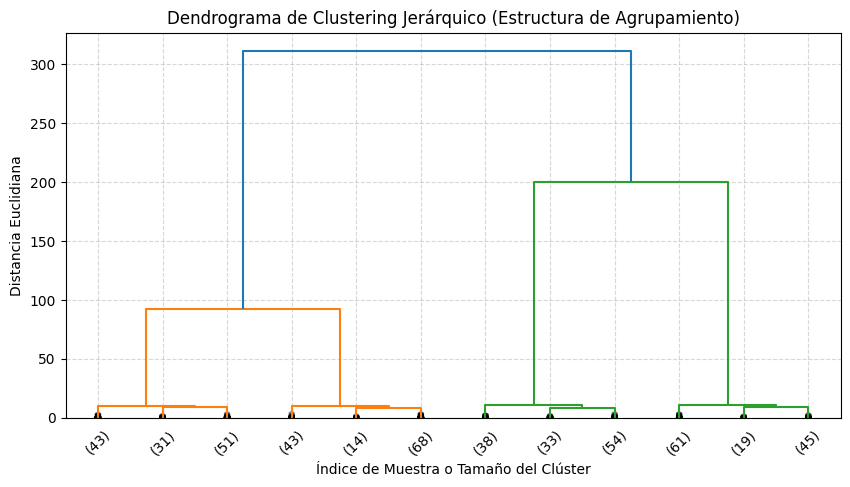


¡Ejecución completada con éxito en Google Colab!


In [5]:
#VISUALIZACIÓN GRÁFICA DE LOS RESULTADOS (Matplotlib)


plt.figure(figsize=(16, 6))

# Gráfica 1: K-Means Clustering sobre PCA
plt.subplot(1, 2, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50, alpha=0.8, edgecolors='k')
plt.scatter(centroides_kmeans[:, 0], centroides_kmeans[:, 1], c='red', marker='X', s=250, label='Centroides K-Means')
plt.title('K-Means Clustering (sobre datos reducidos con PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfica 2: Clustering Jerárquico Aglomerativo
plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_jerarquico, cmap='plasma', s=50, alpha=0.8, edgecolors='k')
plt.title('Clustering Jerárquico Aglomerativo (Ward)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# VISUALIZACIÓN ADICIONAL: DENDROGRAMA (Clustering Jerárquico)

plt.figure(figsize=(10, 5))
matriz_enlace = linkage(X_pca, method='ward')
dendrogram(matriz_enlace, truncate_mode='lastp', p=12, leaf_rotation=45., leaf_font_size=10., show_contracted=True)
plt.title('Dendrograma de Clustering Jerárquico (Estructura de Agrupamiento)')
plt.xlabel('Índice de Muestra o Tamaño del Clúster')
plt.ylabel('Distancia Euclidiana')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("\n¡Ejecución completada con éxito en Google Colab!")